# GRD conference analysis

Cross-source comparison (LVVI3 survey vs. YouTube) prepared for the GRD conference: spatial and temporal distribution, activity popularity and representation bias, and spatial patterns.

- **Inputs**: `data/LVVI3/lvvi3_survey_en.csv` (main LVVI3 survey table), `data/YouTube/nbt_videos_in_state_owned_lands_cleaned.csv` / `nbt_videos_in_state_owned_lands.gpkg`, the archived LLM sub-activity output at `data/_archive/old_llm_subactivity/youtube/YouTube_inferenced.csv`, and `data/boundaries/` geopackages.
- **Notes**: the former facial-recognition (gender/age) analysis was removed because the face-inference outputs no longer exist; only activity-based cross-source comparisons remain.
- **Outputs**: none — analysis only; produces no pipeline artifacts.


# Import packages

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd

import ast
import matplotlib.pyplot as plt

# Read data

## Read LVVI3 data

In [2]:
df_lvvi3 = pd.read_csv('../../data/LVVI3/lvvi3_survey_en.csv')
df_lvvi3 = df_lvvi3.rename(columns={'area_municipality': 'municipality'})

## Read YouTube data

### Read preprocessed data

In [7]:
def read_geofile(path, **kwargs):
    return gpd.read_file(path, engine="pyogrio", **kwargs)

In [8]:
# Read cleaned data and get the video id list
df_videos = pd.read_csv('../../data/YouTube/nbt_videos_in_state_owned_lands_cleaned.csv')
ls_video_id = df_videos.video_id.tolist()

# Read the geopackage file and keep the cleaned data
gdf_videos = read_geofile('../../data/YouTube/nbt_videos_in_state_owned_lands.gpkg')
gdf_videos = gdf_videos[gdf_videos['video_id'].isin(ls_video_id)]
gdf_videos.shape

(6006, 29)

In [9]:
# Read cleaned activity data
df_inferenced = pd.read_csv("../../data/_archive/old_llm_subactivity/youtube/YouTube_inferenced.csv")

df_youtube = df_inferenced.merge(gdf_videos[['video_id', 'title', 'description', 'channel_id', 'channel_title',
                                             'comment_count', 'like_count', 'view_count', 'duration',
                                             'datetime', 'year', 'month', 'year_month', 'municipality',
                                             'nature_reserve', 'national_park', 'wilderness_area', 'commercial_forest',
                                             'geometry']], on='video_id', how='left')

df_youtube = gpd.GeoDataFrame(df_youtube, geometry='geometry')

df_youtube.shape

(8898, 24)

In [10]:
df_youtube = df_youtube.dropna(subset=['activity'])

2010

## Prepare video-level data

In [11]:
df_youtube_cleaned = df_youtube.drop_duplicates(subset='video_id')

df_youtube_cleaned.shape

,channel_id,video_count,age,age_group,gender
842,UCrJygwIZvCQXOgYrwNlkqxA,99,29,25-34,Male
106,UC5pIVp6uyAi7pbWXDySyQMw,34,29,25-34,Male
27,UC16NdAq6BIn7fy7sX2JTWzw,28,29,25-34,Male
569,UCZ2GLsGoD9oqvBClzeseqKg,26,29,25-34,Male
114,UC6G2cmWrqeAqyhy2reO72Xg,26,32,25-34,Male


# Spatial and temporal distribution

## Spatial distribution

In [ ]:
import contextily as ctx
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D

state_lands_path = Path('../../data/boundaries/MH kiinteistot.gpkg')
if not state_lands_path.exists():
    raise FileNotFoundError(f'State-owned lands boundary not found: {state_lands_path}')

state_lands_map = read_geofile(state_lands_path)
youtube_map = df_youtube_cleaned.dropna(subset=['geometry']).copy()

state_lands_web = state_lands_map.to_crs(epsg=3857)
youtube_map_web = youtube_map.to_crs(epsg=3857)

fig, ax = plt.subplots(figsize=(10, 10))
state_lands_web.plot(
    ax=ax,
    color='grey',
    edgecolor='black',
    linewidth=0.3,
    alpha=0.3,
    zorder=2,
 )
youtube_map_web.plot(
    ax=ax,
    color='orange',
    markersize=10,
    zorder=3,
 )

ctx.add_basemap(ax, source=ctx.providers.OpenStreetMap.Mapnik, crs=state_lands_web.crs, zorder=1)

minx, miny, maxx, maxy = state_lands_web.total_bounds
dx = (maxx - minx) * 0.05
dy = (maxy - miny) * 0.05
ax.set_xlim(minx - dx, maxx + dx)
ax.set_ylim(miny - dy, maxy + dy)

legend_handles = [
    mpatches.Patch(facecolor='grey', edgecolor='black', alpha=0.3, label='State-owned lands'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='orange', markersize=7, label='YouTube videos'),
]

map_width = maxx - minx
map_height = maxy - miny
scalebar_length_km = 50
scalebar_length_m = scalebar_length_km * 1000
x_start = minx + map_width * 0.05
y_start = miny + map_height * 0.05
tick_height = map_height * 0.012

ax.plot(
    [x_start, x_start + scalebar_length_m],
    [y_start, y_start],
    color='black',
    linewidth=3,
    zorder=4,
 )
ax.plot(
    [x_start, x_start],
    [y_start, y_start + tick_height],
    color='black',
    linewidth=2,
    zorder=4,
 )
ax.plot(
    [x_start + scalebar_length_m, x_start + scalebar_length_m],
    [y_start, y_start + tick_height],
    color='black',
    linewidth=2,
    zorder=4,
 )
ax.text(
    x_start + scalebar_length_m / 2,
    y_start + tick_height * 1.5,
    f'{scalebar_length_km} km',
    ha='center',
    va='bottom',
    fontsize=9,
    zorder=4,
 )

# ax.set_title('Spatial Distribution of Cleaned YouTube Videos on State-owned Lands')
ax.legend(handles=legend_handles, loc='upper right', frameon=True)
ax.set_axis_off()
plt.tight_layout()

## Temporal distribution

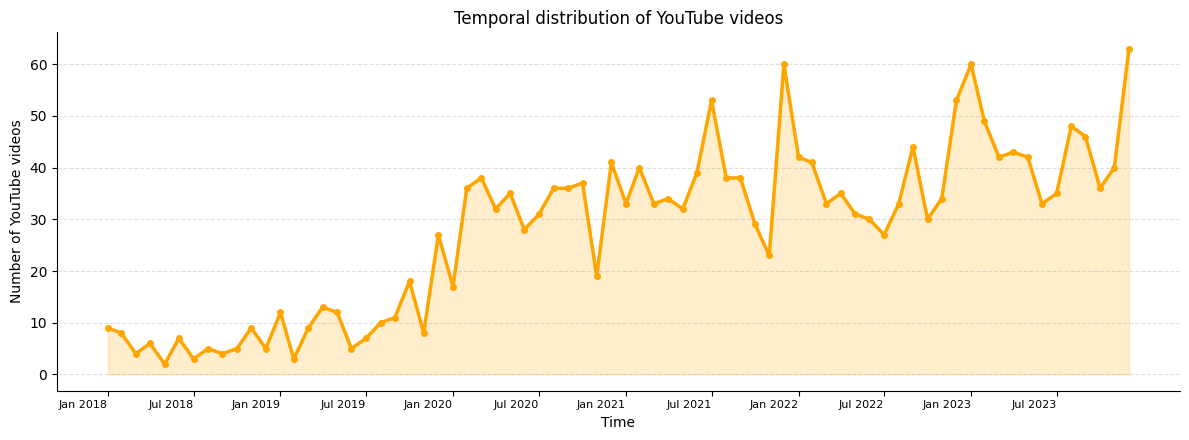

In [ ]:
youtube_temporal = df_youtube_cleaned[['video_id', 'datetime']].copy()
youtube_temporal['datetime'] = pd.to_datetime(youtube_temporal['datetime'], errors='coerce')
youtube_temporal = youtube_temporal.dropna(subset=['datetime']).drop_duplicates(subset='video_id')


monthly_videos = (
    youtube_temporal
    .set_index('datetime')
    .resample('ME')['video_id']
    .nunique()
    .rename('video_count')
    .reset_index()
 )

tick_data = monthly_videos[monthly_videos['datetime'].dt.month.isin([1, 7])].copy()
tick_labels = (
    tick_data['datetime'].dt.strftime('%b %Y')
 )

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(
    monthly_videos['datetime'],
    monthly_videos['video_count'],
    color='orange',
    linewidth=2.5,
    marker='o',
    markersize=4,
 )

ax.fill_between(
    monthly_videos['datetime'],
    monthly_videos['video_count'],
    color='orange',
    alpha=0.2,
 )

ax.set_xticks(tick_data['datetime'])
ax.set_xticklabels(tick_labels, rotation=0, ha='right', fontsize=8)
ax.set_xlabel('Time')
ax.set_ylabel('Number of YouTube videos')
ax.set_title('Temporal distribution of YouTube videos')
ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()

# RQ2: activity popularity

## Activity popularity

In [ ]:
ls_lvvi3_activity = df_lvvi3['activity'].dropna().unique().tolist()

df_youtube[~df_youtube['activity'].isin(ls_lvvi3_activity)]['activity'].value_counts()

activity
Husky safari                158
Sledding                     79
Treasure hunting             71
Reindeer safari              55
Sauna                        39
Flying a drone               31
Northern lights watching     21
Horseback riding             16
Plant                        14
Grilling                     13
Diving                       13
Snowkiting                   11
Bushcraft                     5
Snowsurfing                   5
Snowmobile safari             5
Flying a kite                 5
Paragliding                   4
Acroyoga                      2
Motorbike riding              1
Abseiling                     1
Polar plunge                  1
Rollerblading                 1
Name: count, dtype: int64

In [ ]:
df_youtube['activity'].value_counts()

activity
Walking                                                        969
Camping                                                        467
Staying overnight in a tent, lodge, etc. in natural terrain    446
Picnicking                                                     322
Staying in a summer cottage, farm, holiday home                266
Skiing                                                         264
Nature observation                                             254
Boating                                                        247
Cycling                                                        235
Nature photography                                             231
Outdoor activities with children                               195
Fishing                                                        171
Snowmobiling                                                   167
Husky safari                                                   158
Travelling or staying in a caravan or camper         

### Activity rank

In [ ]:
# Get counts
youtube_counts = df_youtube['activity'].value_counts()
lvvi3_counts = df_lvvi3['activity'].value_counts()

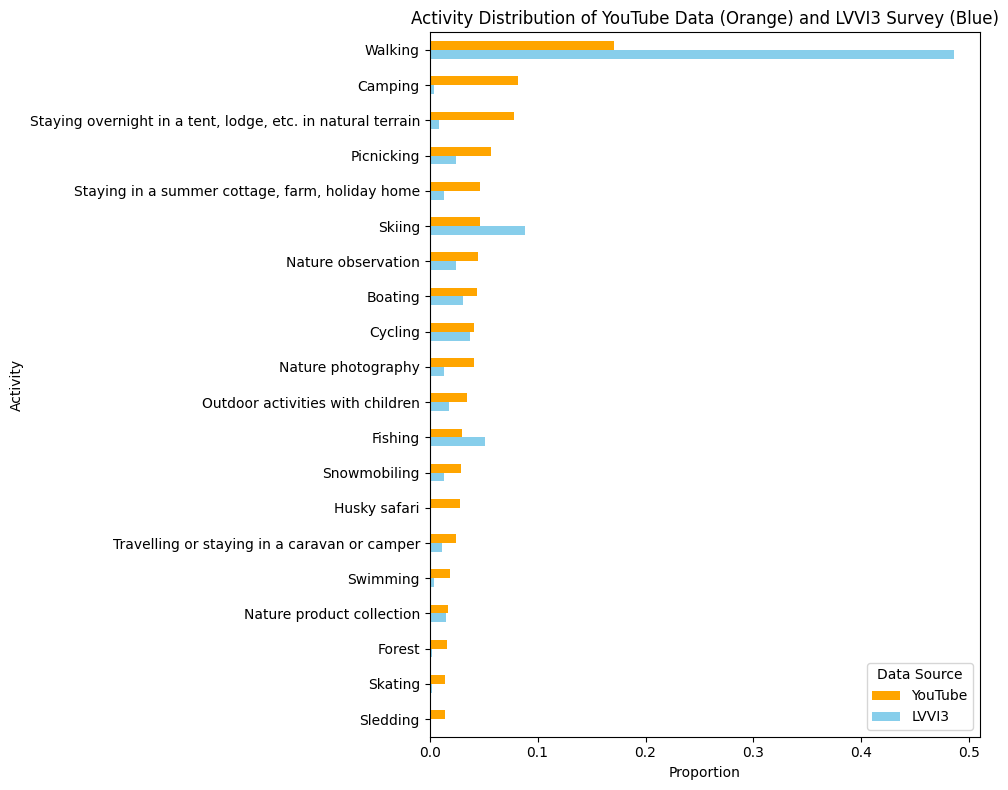

In [ ]:
# Combine counts
combined = pd.DataFrame({
    'YouTube': youtube_counts,
    'LVVI3': lvvi3_counts,
}).fillna(0)

# Normalize
combined = combined / combined.sum()

# Sort by YouTube
combined = combined.sort_values('YouTube', ascending=True).tail(20)

# Reorder columns so YouTube is ABOVE
combined = combined[['LVVI3', 'YouTube']]

# Plot
ax = combined.plot(
    kind='barh',
    figsize=(10, 8),
    color=['skyblue', 'orange']
)

plt.title('Activity Distribution of YouTube Data (Orange) and LVVI3 Survey (Blue)')
plt.xlabel('Proportion')
plt.ylabel('Activity')

# --- legend ---
handles, labels = ax.get_legend_handles_labels()
order = [1, 0]

plt.legend(
    [handles[i] for i in order],
    [labels[i] for i in order],
    title='Data Source'
)

plt.tight_layout()
plt.show()

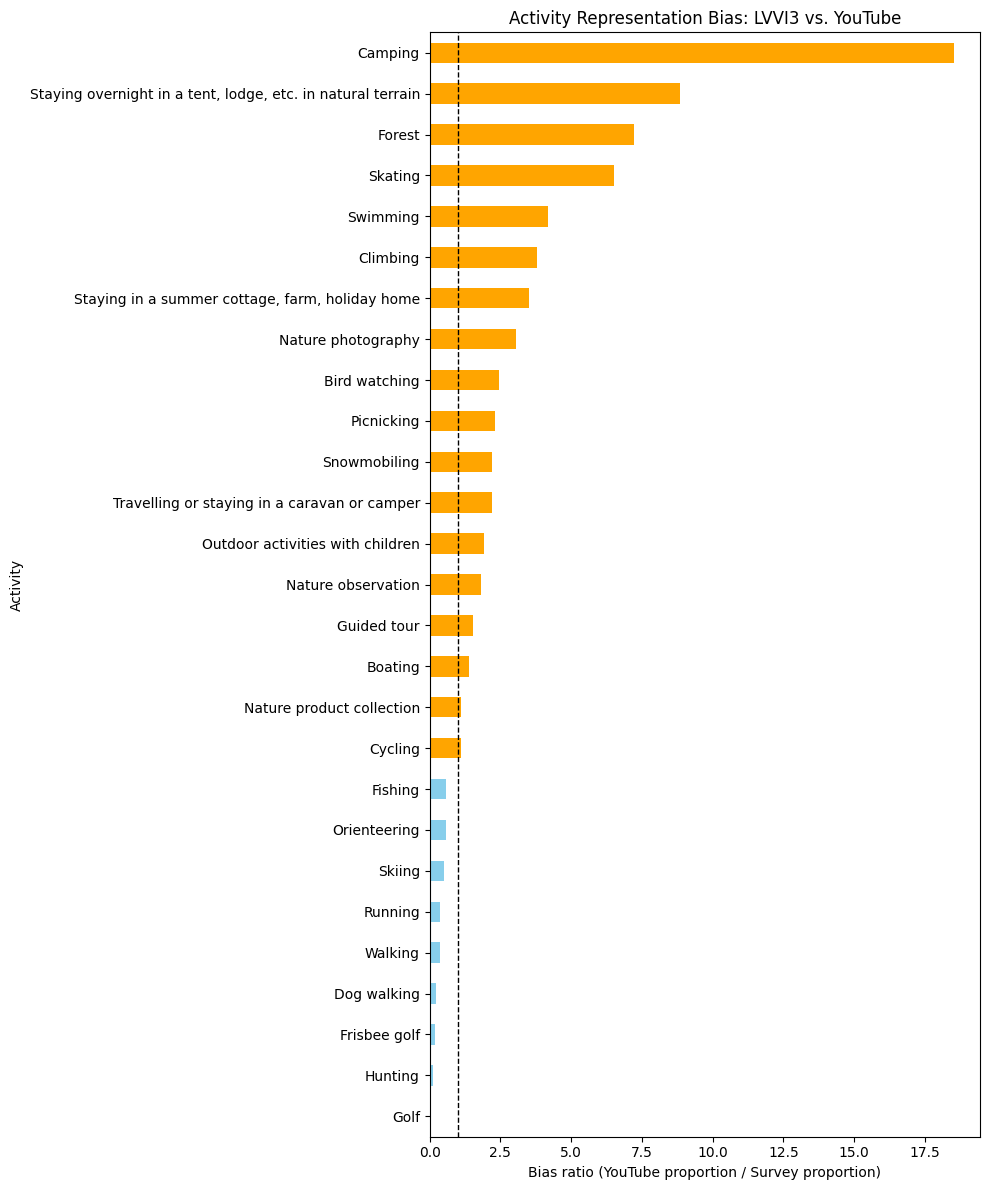

In [ ]:
df_bias = pd.DataFrame({
    'YouTube_count': youtube_counts,
    'LVVI3_count': lvvi3_counts,
}).fillna(0)

df_bias['YouTube_prop'] = df_bias['YouTube_count'] / df_bias['YouTube_count'].sum()
df_bias['LVVI3_prop'] = df_bias['LVVI3_count'] / df_bias['LVVI3_count'].sum()
df_bias['bias'] = df_bias['YouTube_prop'] / df_bias['LVVI3_prop'].replace(0, pd.NA)
df_bias = df_bias.dropna(subset=['bias']).sort_values('bias')

colors = np.where(df_bias['bias'] > 1, 'orange', 'skyblue')

ax = df_bias['bias'].plot(
    kind='barh',
    figsize=(10, 12),
    color=colors,
 )
ax.axvline(1, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Bias ratio (YouTube proportion / Survey proportion)')
ax.set_ylabel('Activity')
ax.set_title('Activity Representation Bias: LVVI3 vs. YouTube')
plt.tight_layout()
plt.show()

In [ ]:
# Convert to ranks
youtube_rank = youtube_counts.rank(ascending=False, method='min')
lvvi3_rank = lvvi3_counts.rank(ascending=False, method='min')

# Combine
rank_df = pd.DataFrame({
    'YouTube': youtube_rank,
    'LVVI3': lvvi3_rank
}).dropna()

# Keep top N (based on YouTube for consistency)
rank_df = rank_df.sort_values('YouTube').head(50)

Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


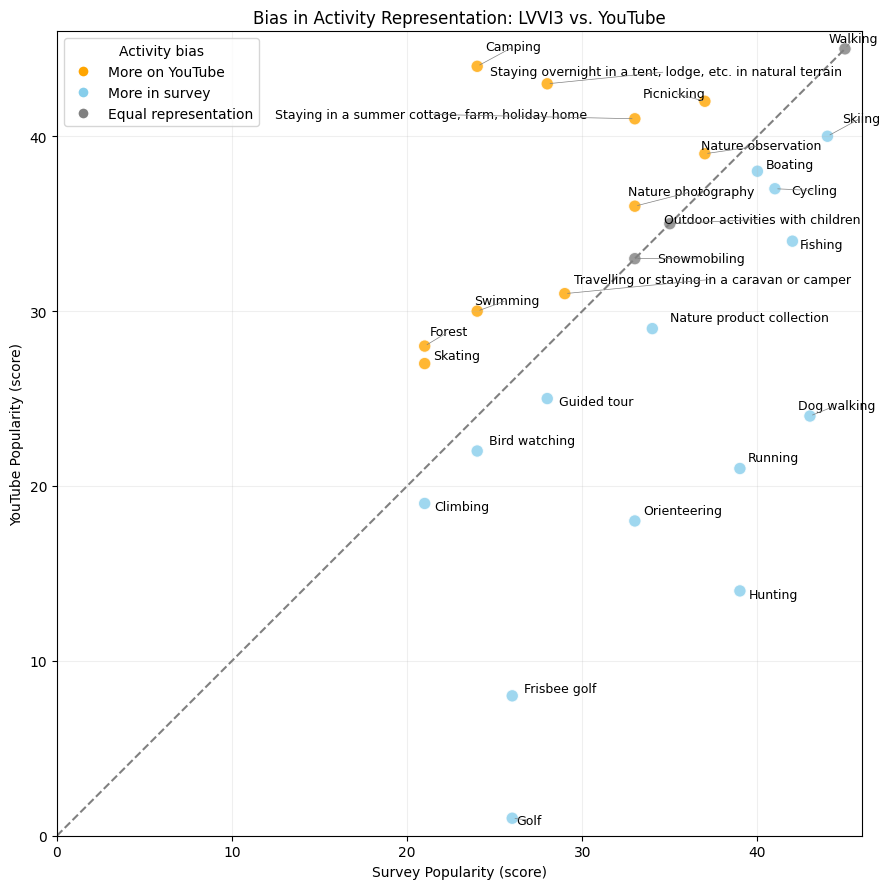

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from adjustText import adjust_text
from matplotlib.lines import Line2D

plt.figure(figsize=(9, 9))

# --- Convert rank -> score (higher = more popular) ---
max_rank = int(rank_df[['LVVI3', 'YouTube']].max().max())

rank_df['LVVI3_score'] = max_rank + 1 - rank_df['LVVI3']
rank_df['YouTube_score'] = max_rank + 1 - rank_df['YouTube']

# --- Compute difference ---
rank_df['diff'] = rank_df['YouTube_score'] - rank_df['LVVI3_score']

# --- Color by bias ---
colors = np.where(
    rank_df['diff'] > 0,
    'orange',
    np.where(rank_df['diff'] < 0, 'skyblue', 'gray'),
)

# --- Scatter ---
plt.scatter(
    rank_df['LVVI3_score'],
    rank_df['YouTube_score'],
    c=colors,
    alpha=0.8,
    s=80,
    edgecolor='white',
    linewidth=0.8,
 )

# --- Diagonal reference line ---
max_score = rank_df[['LVVI3_score', 'YouTube_score']].max().max()
plt.plot([0, max_score], [0, max_score], linestyle='--', color='gray')

texts = []
for activity in rank_df.index:
    x = rank_df.loc[activity, 'LVVI3_score']
    y = rank_df.loc[activity, 'YouTube_score']
    texts.append(plt.text(x, y, activity, fontsize=9))

adjust_text(
    texts,
    arrowprops=dict(arrowstyle='-', color='gray', lw=0.5),
    expand_points=(1.2, 1.2),
)

# Set the axis limits to start at 0
plt.xlim(0, max_score + 1)
plt.ylim(0, max_score + 1)

# --- Labels & title ---
plt.xlabel('Survey Popularity (score)')
plt.ylabel('YouTube Popularity (score)')
plt.title('Bias in Activity Representation: LVVI3 vs. YouTube')

# --- Legend ---
legend_handles = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='orange', markersize=8, label='More on YouTube'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='skyblue', markersize=8, label='More in survey'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', markersize=8, label='Equal representation'),
]
plt.legend(handles=legend_handles, title='Activity bias')

# --- Clean look ---
plt.grid(alpha=0.2)
plt.tight_layout()

plt.show()

In [38]:
from scipy.stats import pearsonr, spearmanr

# Rebuild the rank table used in the scatter plot so the analysis matches the plotted activities.
youtube_rank = youtube_counts.rank(ascending=False, method='min')
lvvi3_rank = lvvi3_counts.rank(ascending=False, method='min')

rank_compare = pd.DataFrame({
    'YouTube_rank': youtube_rank,
    'LVVI3_rank': lvvi3_rank,
}).dropna()
rank_compare = rank_compare.sort_values('YouTube_rank').head(50)

# Build aligned activity-count data for the same plotted activities.
count_compare = pd.DataFrame({
    'YouTube_count': youtube_counts,
    'LVVI3_count': lvvi3_counts,
}).loc[rank_compare.index].copy()
count_compare['YouTube_log_count'] = np.log1p(count_compare['YouTube_count'])
count_compare['LVVI3_log_count'] = np.log1p(count_compare['LVVI3_count'])

spearman_stat, spearman_p = spearmanr(
    rank_compare['LVVI3_rank'],
    rank_compare['YouTube_rank'],
)
pearson_stat, pearson_p = pearsonr(
    count_compare['LVVI3_log_count'],
    count_compare['YouTube_log_count'],
)

test_outputs = [
    {
        'analysis': 'Spearman correlation of activity rank',
        'variables': 'LVVI3 rank vs YouTube rank',
        'sample_size': len(rank_compare),
        'statistic': spearman_stat,
        'p_value': spearman_p,
    },
    {
        'analysis': 'Pearson correlation of log-transformed activity count',
        'variables': 'log1p(LVVI3 count) vs log1p(YouTube count)',
        'sample_size': len(count_compare),
        'statistic': pearson_stat,
        'p_value': pearson_p,
    },
]

activity_correlation_results = pd.DataFrame(test_outputs)
activity_correlation_results['statistic'] = activity_correlation_results['statistic'].map(lambda value: f'{value:.3f}')
activity_correlation_results['p_value'] = activity_correlation_results['p_value'].map(lambda value: f'{value:.4g}')

print('Activity correlation analysis for the plotted cross-dataset scatter data')
display(activity_correlation_results)

print('Rank comparison table used in the Spearman test')
display(rank_compare.head(10))

print('Count comparison table used in the Pearson test (log1p transformed)')
display(count_compare.head(10))

Activity correlation analysis for the plotted cross-dataset scatter data


,analysis,variables,sample_size,statistic,p_value
0,Spearman correlation of activity rank,LVVI3 rank vs YouTube rank,27,0.343,0.08011
1,Pearson correlation of log-transformed activit...,log1p(LVVI3 count) vs log1p(YouTube count),27,0.407,0.03531


Rank comparison table used in the Spearman test


,YouTube_rank,LVVI3_rank
activity,,
Walking,1.0,1.0
Camping,2.0,22.0
"Staying overnight in a tent, lodge, etc. in natural terrain",3.0,18.0
Picnicking,4.0,9.0
"Staying in a summer cottage, farm, holiday home",5.0,13.0
Skiing,6.0,2.0
Nature observation,7.0,9.0
Boating,8.0,6.0
Cycling,9.0,5.0


Count comparison table used in the Pearson test (log1p transformed)


,YouTube_count,LVVI3_count,YouTube_log_count,LVVI3_log_count
activity,,,,
Walking,969,219.0,6.877296,5.393628
Camping,467,2.0,6.148468,1.098612
"Staying overnight in a tent, lodge, etc. in natural terrain",446,4.0,6.102559,1.609438
Picnicking,322,11.0,5.777652,2.484907
"Staying in a summer cottage, farm, holiday home",266,6.0,5.587249,1.945910
Skiing,264,40.0,5.579730,3.713572
Nature observation,254,11.0,5.541264,2.484907
Boating,247,14.0,5.513429,2.708050
Cycling,235,17.0,5.463832,2.890372


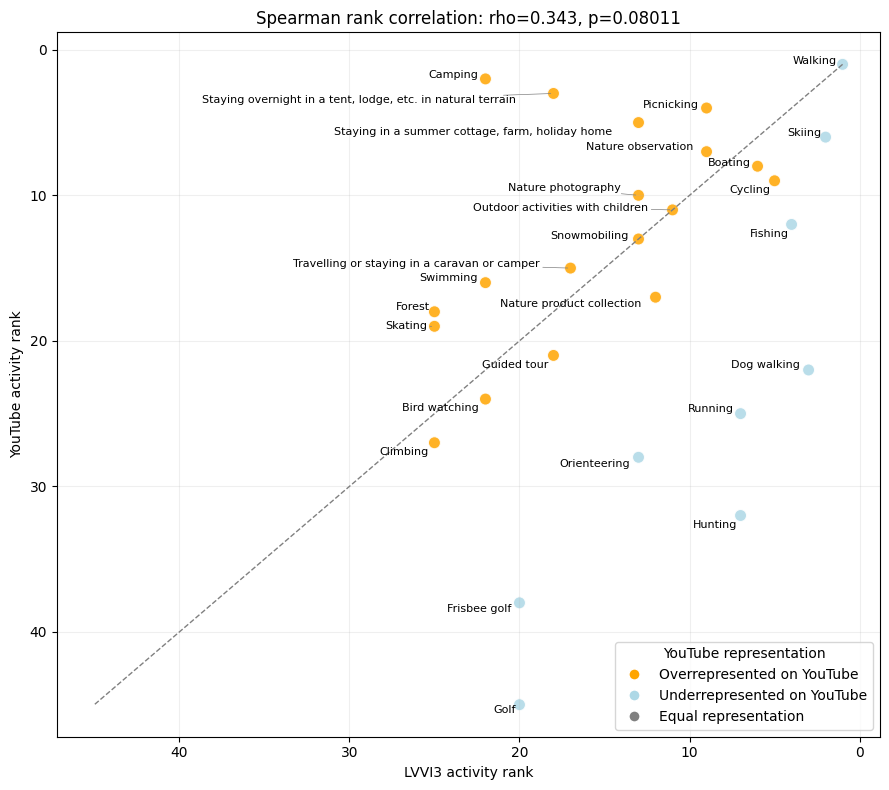

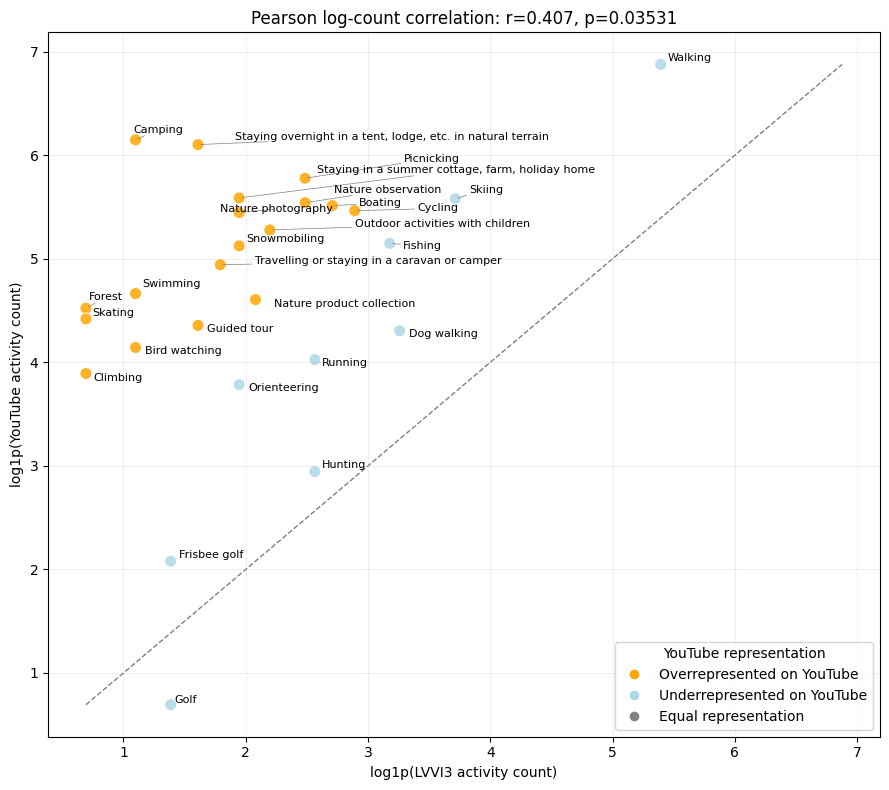

In [40]:
from matplotlib.lines import Line2D

activity_bias_status = df_bias[['bias']].copy()
activity_bias_status['representation'] = np.where(
    activity_bias_status['bias'] > 1,
    'overrepresented',
    np.where(activity_bias_status['bias'] < 1, 'underrepresented', 'balanced'),
)

rank_plot = rank_compare.merge(
    activity_bias_status[['representation']],
    left_index=True,
    right_index=True,
    how='left',
)
rank_plot['representation'] = rank_plot['representation'].fillna('balanced')
rank_plot['point_color'] = rank_plot['representation'].map(
    {
        'overrepresented': 'orange',
        'underrepresented': 'lightblue',
        'balanced': 'gray',
    }
)

count_plot = count_compare.merge(
    activity_bias_status[['representation']],
    left_index=True,
    right_index=True,
    how='left',
)
count_plot['representation'] = count_plot['representation'].fillna('balanced')
count_plot['point_color'] = count_plot['representation'].map(
    {
        'overrepresented': 'orange',
        'underrepresented': 'lightblue',
        'balanced': 'gray',
    }
)

legend_handles = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='orange', markersize=8, label='Overrepresented on YouTube'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='lightblue', markersize=8, label='Underrepresented on YouTube'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', markersize=8, label='Equal representation'),
]

# Scatter plot for Spearman rank correlation
fig, spearman_ax = plt.subplots(figsize=(9, 8))
spearman_ax.scatter(
    rank_plot['LVVI3_rank'],
    rank_plot['YouTube_rank'],
    c=rank_plot['point_color'],
    alpha=0.85,
    s=75,
    edgecolor='white',
    linewidth=0.8,
)

rank_min = min(rank_plot['LVVI3_rank'].min(), rank_plot['YouTube_rank'].min())
rank_max = max(rank_plot['LVVI3_rank'].max(), rank_plot['YouTube_rank'].max())
spearman_ax.plot([rank_min, rank_max], [rank_min, rank_max], linestyle='--', color='gray', linewidth=1)

rank_texts = []
for activity in rank_plot.index:
    rank_texts.append(
        spearman_ax.text(
            rank_plot.loc[activity, 'LVVI3_rank'],
            rank_plot.loc[activity, 'YouTube_rank'],
            activity,
            fontsize=8,
        )
    )

adjust_text(
    rank_texts,
    ax=spearman_ax,
    arrowprops=dict(arrowstyle='-', color='gray', lw=0.5),
)

spearman_ax.set_xlabel('LVVI3 activity rank')
spearman_ax.set_ylabel('YouTube activity rank')
spearman_ax.set_title(f'Spearman rank correlation: rho={spearman_stat:.3f}, p={spearman_p:.4g}')
spearman_ax.grid(alpha=0.2)
spearman_ax.legend(handles=legend_handles, title='YouTube representation')
spearman_ax.invert_xaxis()
spearman_ax.invert_yaxis()
plt.tight_layout()
plt.show()

# Scatter plot for Pearson correlation on log-transformed counts
fig, pearson_ax = plt.subplots(figsize=(9, 8))
pearson_ax.scatter(
    count_plot['LVVI3_log_count'],
    count_plot['YouTube_log_count'],
    c=count_plot['point_color'],
    alpha=0.85,
    s=75,
    edgecolor='white',
    linewidth=0.8,
)

log_min = min(count_plot['LVVI3_log_count'].min(), count_plot['YouTube_log_count'].min())
log_max = max(count_plot['LVVI3_log_count'].max(), count_plot['YouTube_log_count'].max())
pearson_ax.plot([log_min, log_max], [log_min, log_max], linestyle='--', color='gray', linewidth=1)

pearson_texts = []
for activity in count_plot.index:
    pearson_texts.append(
        pearson_ax.text(
            count_plot.loc[activity, 'LVVI3_log_count'],
            count_plot.loc[activity, 'YouTube_log_count'],
            activity,
            fontsize=8,
        )
    )

adjust_text(
    pearson_texts,
    ax=pearson_ax,
    arrowprops=dict(arrowstyle='-', color='gray', lw=0.5),
)

pearson_ax.set_xlabel('log1p(LVVI3 activity count)')
pearson_ax.set_ylabel('log1p(YouTube activity count)')
pearson_ax.set_title(f'Pearson log-count correlation: r={pearson_stat:.3f}, p={pearson_p:.4g}')
pearson_ax.grid(alpha=0.2)
pearson_ax.legend(handles=legend_handles, title='YouTube representation')
plt.tight_layout()
plt.show()

In [ ]:
df_lvvi3.activity.value_counts()

activity
Walking                                                        219
Skiing                                                          40
Dog walking                                                     25
Fishing                                                         23
Cycling                                                         17
Boating                                                         14
Running                                                         12
Hunting                                                         12
Picnicking                                                      11
Nature observation                                              11
Outdoor activities with children                                 8
Nature product collection                                        7
Staying in a summer cottage, farm, holiday home                  6
Snowmobiling                                                     6
Nature photography                                   

# RQ3: spatial patterns

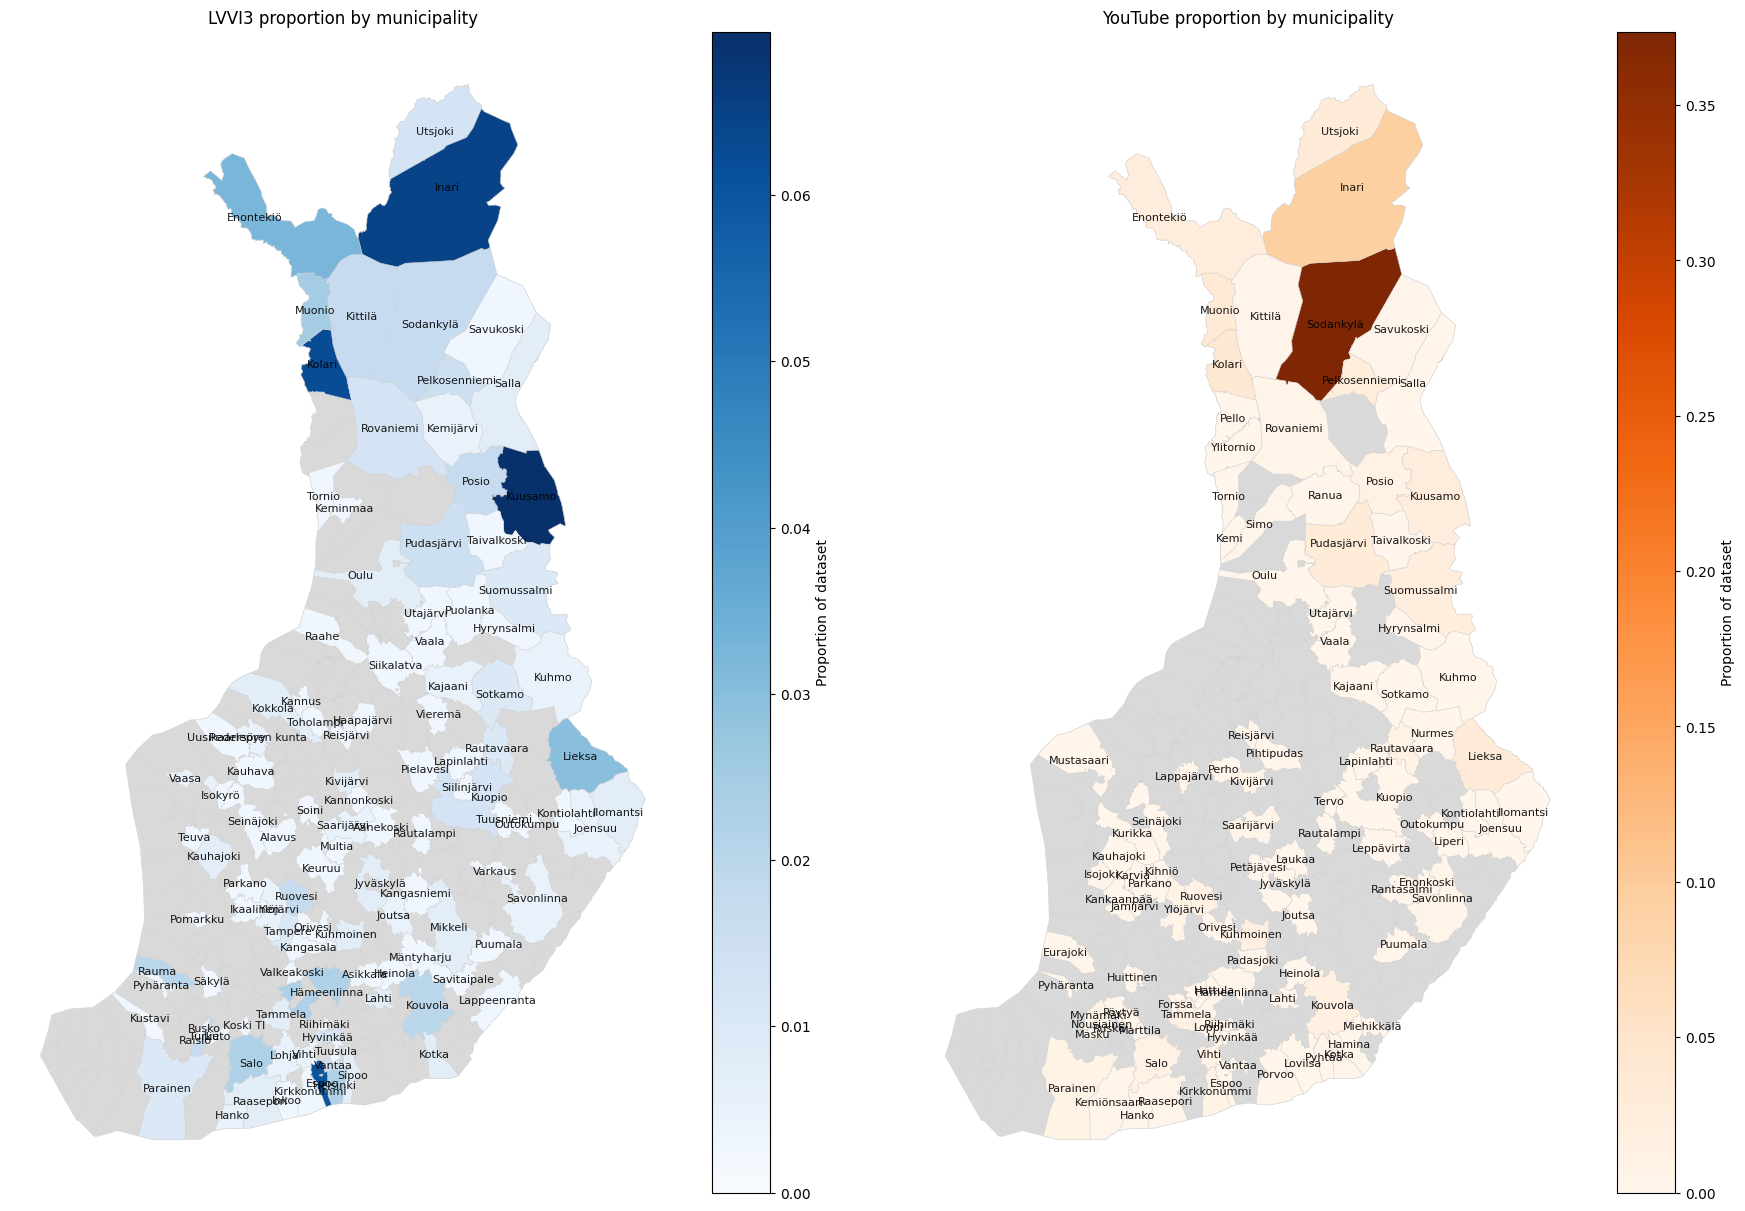

In [60]:
municipality_boundaries = read_geofile(
    '../../data/boundaries/SuomenHallinnollisetKuntajakopohjaisetAluejaot_2026_10k.gpkg',
    layer='Kunta',
)
municipality_boundaries = municipality_boundaries[['namefin', 'geometry']].rename(columns={'namefin': 'municipality'})
municipality_boundaries['municipality'] = municipality_boundaries['municipality'].astype('string').str.strip()
municipality_boundaries['label_point'] = municipality_boundaries.representative_point()

lvvi3_municipality_counts = (
    df_lvvi3[['municipality']]
    .dropna(subset=['municipality'])
    .assign(municipality=lambda df: df['municipality'].astype('string').str.strip())
    .groupby('municipality')
    .size()
    .rename('count')
    .reset_index()
)
lvvi3_total = lvvi3_municipality_counts['count'].sum()
lvvi3_municipality_counts['proportion'] = lvvi3_municipality_counts['count'] / lvvi3_total

youtube_municipality_counts = (
    df_youtube_cleaned[['video_id', 'municipality']]
    .dropna(subset=['municipality'])
    .drop_duplicates(subset=['video_id'])
    .assign(municipality=lambda df: df['municipality'].astype('string').str.strip())
    .groupby('municipality')
    .size()
    .rename('count')
    .reset_index()
)
youtube_total = youtube_municipality_counts['count'].sum()
youtube_municipality_counts['proportion'] = youtube_municipality_counts['count'] / youtube_total

lvvi3_municipality_map = municipality_boundaries.merge(
    lvvi3_municipality_counts,
    on='municipality',
    how='left',
)
youtube_municipality_map = municipality_boundaries.merge(
    youtube_municipality_counts,
    on='municipality',
    how='left',
)

for gdf_map in [lvvi3_municipality_map, youtube_municipality_map]:
    gdf_map['count'] = gdf_map['count'].fillna(0)
    gdf_map['proportion'] = gdf_map['proportion'].fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(18, 12), constrained_layout=True)
map_specs = [
    (axes[0], lvvi3_municipality_map, 'Blues', 'LVVI3 proportion by municipality'),
    (axes[1], youtube_municipality_map, 'Oranges', 'YouTube proportion by municipality'),
]

for ax, gdf_map, cmap, title in map_specs:
    gdf_map.plot(
        color='#d9d9d9',
        linewidth=0.35,
        edgecolor='lightgrey',
        ax=ax,
    )

    gdf_map[gdf_map['count'] > 0].plot(
        column='proportion',
        cmap=cmap,
        linewidth=0.35,
        edgecolor='lightgrey',
        legend=True,
        ax=ax,
        vmin=0,
        legend_kwds={'label': 'Proportion of dataset'},
    )

    for row in gdf_map[gdf_map['count'] > 0].itertuples():
        ax.text(
            row.label_point.x,
            row.label_point.y,
            row.municipality,
            fontsize=8,
            color='black',
            ha='center',
            va='center',
            alpha=0.9,
        )

    ax.set_title(title)
    ax.set_axis_off()

plt.show()

,municipality,survey_share,youtube_share,representation_ratio,representation_status
125,Hyrynsalmi,0.002494,0.002488,0.997512,Survey overrepresented
244,Savonlinna,0.004988,0.004478,0.897761,Survey overrepresented
184,Kouvola,0.019950,0.017413,0.872823,Survey overrepresented
0,Parainen,0.009975,0.007960,0.798010,Survey overrepresented
119,Rusko,0.002494,0.001990,0.798010,Survey overrepresented
...,...,...,...,...,...
294,Inari,0.064838,0.094527,1.457903,YouTube overrepresented
29,Muonio,0.024938,0.036318,1.456368,YouTube overrepresented
227,Savukoski,0.002494,0.003483,1.396517,YouTube overrepresented
242,Rautavaara,0.009975,0.010945,1.097264,YouTube overrepresented


representation_status
Survey overrepresented     99
YouTube overrepresented    55
Name: count, dtype: int64


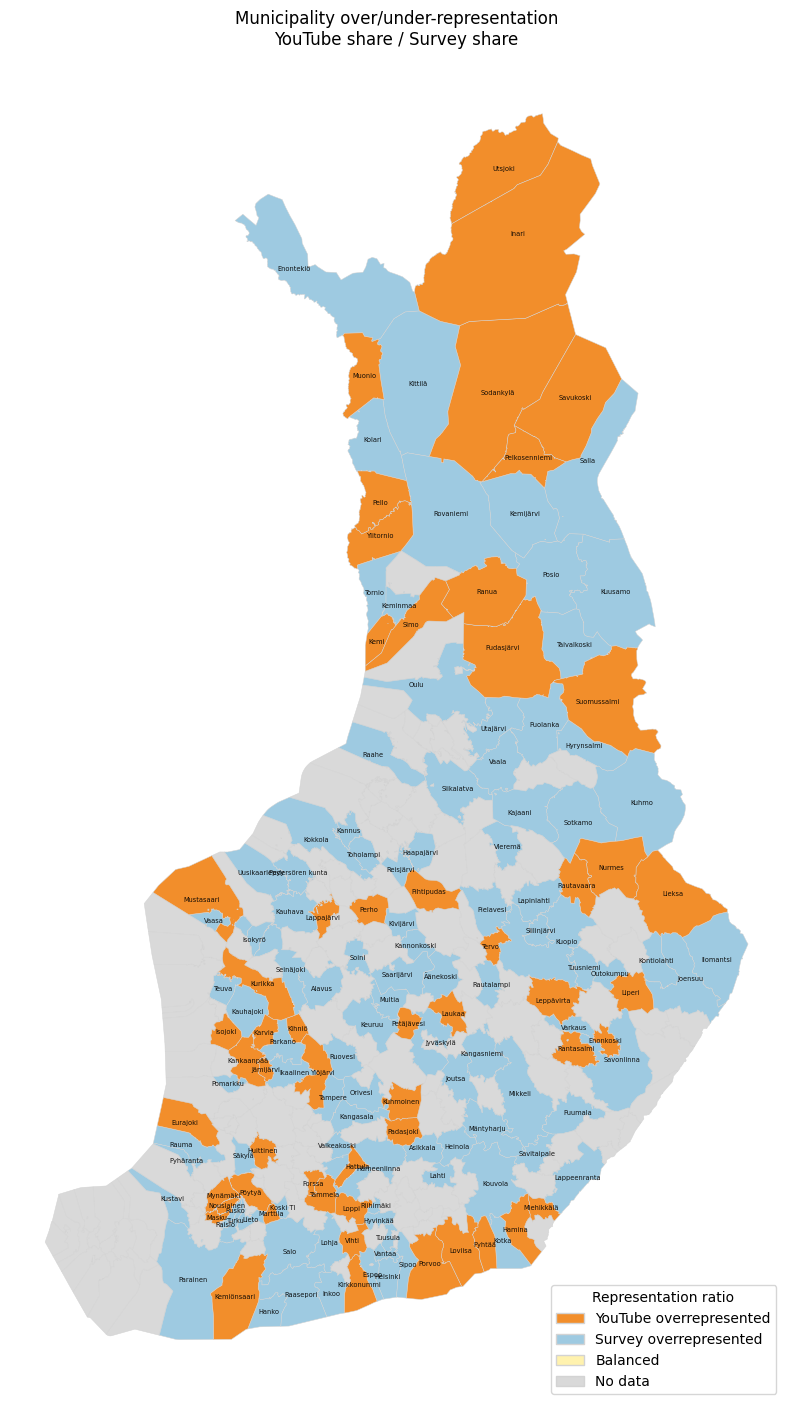

In [80]:
from matplotlib.patches import Patch

municipality_representation = municipality_boundaries[[
    'municipality',
    'geometry',
    'label_point',
]].copy()
municipality_representation = municipality_representation.merge(
    lvvi3_municipality_counts[['municipality', 'proportion']].rename(columns={'proportion': 'survey_share'}),
    on='municipality',
    how='left',
)
municipality_representation = municipality_representation.merge(
    youtube_municipality_counts[['municipality', 'proportion']].rename(columns={'proportion': 'youtube_share'}),
    on='municipality',
    how='left',
)
municipality_representation[['survey_share', 'youtube_share']] = municipality_representation[[
    'survey_share',
    'youtube_share',
]].fillna(0)

municipality_representation['representation_ratio'] = np.where(
    municipality_representation['survey_share'] > 0,
    municipality_representation['youtube_share'] / municipality_representation['survey_share'],
    np.where(municipality_representation['youtube_share'] > 0, np.inf, np.nan),
)

municipality_representation['representation_status'] = 'No data'
municipality_representation.loc[
    (municipality_representation['youtube_share'] > 0) & (municipality_representation['survey_share'] == 0),
    'representation_status',
] = 'YouTube overrepresented'
municipality_representation.loc[
    (municipality_representation['youtube_share'] == 0) & (municipality_representation['survey_share'] > 0),
    'representation_status',
] = 'Survey overrepresented'
municipality_representation.loc[
    (municipality_representation['youtube_share'] > 0)
    & (municipality_representation['survey_share'] > 0)
    & (municipality_representation['representation_ratio'] > 1),
    'representation_status',
] = 'YouTube overrepresented'
municipality_representation.loc[
    (municipality_representation['youtube_share'] > 0)
    & (municipality_representation['survey_share'] > 0)
    & (municipality_representation['representation_ratio'] < 1),
    'representation_status',
] = 'Survey overrepresented'
municipality_representation.loc[
    (municipality_representation['youtube_share'] > 0)
    & (municipality_representation['survey_share'] > 0)
    & np.isclose(municipality_representation['representation_ratio'], 1),
    'representation_status',
] = 'Balanced'

ratio_table = municipality_representation[[
    'municipality',
    'survey_share',
    'youtube_share',
    'representation_ratio',
    'representation_status',
]].copy()
ratio_table = ratio_table[ratio_table['representation_status'] != 'No data'].sort_values(
    by=['representation_status', 'representation_ratio'],
    ascending=[True, False],
)

display(ratio_table)
print(ratio_table['representation_status'].value_counts())

status_colors = {
    'YouTube overrepresented': '#f28e2b',
    'Survey overrepresented': '#9ecae1',
    'Balanced': '#fff2ae',
    'No data': '#d9d9d9',
}
status_order = [
    'YouTube overrepresented',
    'Survey overrepresented',
    'Balanced',
    'No data',
]

fig, ax = plt.subplots(figsize=(10, 14), constrained_layout=True)

for status in status_order[::-1]:
    status_gdf = municipality_representation[
        municipality_representation['representation_status'] == status
    ]
    if status_gdf.empty:
        continue

    status_gdf.plot(
        color=status_colors[status],
        linewidth=0.35,
        edgecolor='lightgrey',
        ax=ax,
    )

for row in municipality_representation[
    municipality_representation['representation_status'] != 'No data'
].itertuples():
    ax.text(
        row.label_point.x,
        row.label_point.y,
        row.municipality,
        fontsize=4.8,
        color='black',
        ha='center',
        va='center',
        alpha=0.9,
    )

legend_handles = [
    Patch(facecolor=status_colors[status], edgecolor='lightgrey', label=status)
    for status in status_order
]
ax.legend(handles=legend_handles, title='Representation ratio', loc='lower right')
ax.set_title('Municipality over/under-representation\nYouTube share / Survey share')
ax.set_axis_off()

plt.show()

In [79]:
from scipy.stats import spearmanr

municipality_rank_compare = municipality_boundaries[['municipality']].copy()
municipality_rank_compare = municipality_rank_compare.merge(
    lvvi3_municipality_counts[['municipality', 'count', 'proportion']].rename(
        columns={'count': 'survey_count', 'proportion': 'survey_share'}
    ),
    on='municipality',
    how='left',
)
municipality_rank_compare = municipality_rank_compare.merge(
    youtube_municipality_counts[['municipality', 'count', 'proportion']].rename(
        columns={'count': 'youtube_count', 'proportion': 'youtube_share'}
    ),
    on='municipality',
    how='left',
)
municipality_rank_compare[['survey_count', 'survey_share', 'youtube_count', 'youtube_share']] = (
    municipality_rank_compare[['survey_count', 'survey_share', 'youtube_count', 'youtube_share']].fillna(0)
)

municipality_rank_compare = municipality_rank_compare[
    (municipality_rank_compare['survey_count'] > 0) | (municipality_rank_compare['youtube_count'] > 0)
].copy()

municipality_rank_compare['survey_rank'] = municipality_rank_compare['survey_share'].rank(
    ascending=False,
    method='average',
)
municipality_rank_compare['youtube_rank'] = municipality_rank_compare['youtube_share'].rank(
    ascending=False,
    method='average',
)

spearman_stat, spearman_p = spearmanr(
    municipality_rank_compare['survey_rank'],
    municipality_rank_compare['youtube_rank'],
)

municipality_rank_correlation = pd.DataFrame(
    [
        {
            'analysis': 'Spearman correlation of municipality rank',
            'variables': 'Survey municipality rank vs YouTube municipality rank',
            'sample_size': len(municipality_rank_compare),
            'rho': spearman_stat,
            'p_value': spearman_p,
        }
    ]
)
municipality_rank_correlation['rho'] = municipality_rank_correlation['rho'].map(lambda value: f'{value:.3f}')
municipality_rank_correlation['p_value'] = municipality_rank_correlation['p_value'].map(lambda value: f'{value:.4g}')

print('Municipality rank correlation between the survey and YouTube datasets')
display(municipality_rank_correlation)

municipality_rank_compare = municipality_rank_compare.sort_values('survey_rank')
display(
    municipality_rank_compare[[
        'municipality',
        'survey_count',
        'youtube_count',
        'survey_share',
        'youtube_share',
        'survey_rank',
        'youtube_rank',
    ]].head(20)
)

Municipality rank correlation between the survey and YouTube datasets


,analysis,variables,sample_size,rho,p_value
0,Spearman correlation of municipality rank,Survey municipality rank vs YouTube municipali...,154,0.248,0.001928


,municipality,survey_count,youtube_count,survey_share,youtube_share,survey_rank,youtube_rank
87,Kuusamo,28.0,48.0,0.069825,0.023881,1.0,10.0
294,Inari,26.0,190.0,0.064838,0.094527,2.0,2.0
18,Kolari,25.0,85.0,0.062344,0.042289,3.0,3.0
300,Espoo,24.0,1.0,0.059850,0.000498,4.0,87.5
23,Enontekiö,13.0,49.0,0.032419,0.024378,5.0,9.0
203,Lieksa,12.0,65.0,0.029925,0.032338,6.0,5.0
29,Muonio,10.0,73.0,0.024938,0.036318,7.0,4.0
116,Helsinki,9.0,0.0,0.022444,0.000000,9.0,130.0
173,Salo,9.0,28.0,0.022444,0.013930,9.0,14.0
12,Hämeenlinna,9.0,6.0,0.022444,0.002985,9.0,36.5
